In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_excel("netflix_titles.xlsx")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 8807
Number of columns: 12


In [4]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25 00:00:00,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24 00:00:00,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,2021-09-24 00:00:00,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,2021-09-24 00:00:00,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24 00:00:00,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [6]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [7]:
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

print(missing_values)

director      2634
cast           825
country        831
date_added      10
rating           4
duration         3
dtype: int64


In [8]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [9]:
df_clean = df.copy()
columns_to_fill = [
    "director",
    "cast",
    "country",
    "rating"
]

for column in columns_to_fill:
    df_clean[column] = df_clean[column].fillna("Unknown")

print("Missing text values handled successfully!")

Missing text values handled successfully!


In [10]:
# Convert date_added to datetime format
df_clean["date_added"] = pd.to_datetime(
    df_clean["date_added"],
    errors="coerce"
)

print("Date column converted successfully!")
print(df_clean["date_added"].dtype)

Date column converted successfully!
datetime64[ns]


In [11]:
# Extract the year a title was added to Netflix
df_clean["year_added"] = df_clean["date_added"].dt.year

df_clean[["title", "date_added", "year_added"]].head()

,title,date_added,year_added
0,Dick Johnson Is Dead,2021-09-25,2021.0
1,Blood & Water,2021-09-24,2021.0
2,Ganglands,2021-09-24,2021.0
3,Jailbirds New Orleans,2021-09-24,2021.0
4,Kota Factory,2021-09-24,2021.0


In [12]:
print("Dataset shape:", df_clean.shape)

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

Dataset shape: (8807, 13)

Missing values after cleaning:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         3
listed_in        0
description      0
year_added      10
dtype: int64


In [13]:
df_clean.to_csv("netflix_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [14]:
from google.colab import files

files.download("netflix_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


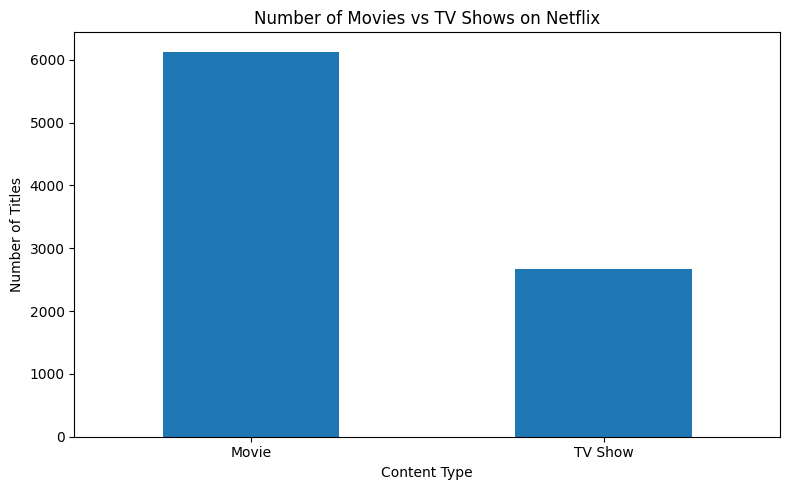

In [15]:
# Count movies and TV shows
content_counts = df_clean["type"].value_counts()

print(content_counts)

plt.figure(figsize=(8, 5))
content_counts.plot(kind="bar")

plt.title("Number of Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Insight 1: Distribution of Movies and TV Shows

The analysis of 8,807 Netflix titles shows that the catalog contains 6,131 movies and 2,676 TV shows. Movies account for approximately 69.6% of the catalog, compared with 30.4% for TV shows. This suggests that movies represent the larger share of Netflix's content library. Further analysis of genres and release trends can help identify opportunities to diversify content offerings.
Is this need to be add and to add one final summary at last

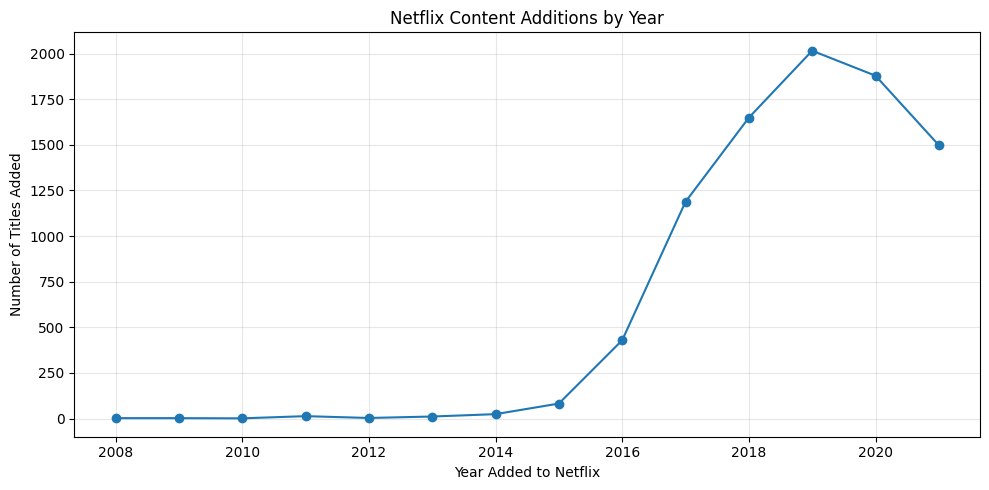

year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      24
2015.0      82
2016.0     429
2017.0    1188
2018.0    1649
2019.0    2016
2020.0    1879
2021.0    1498
dtype: int64


In [16]:
# Count titles added each year
yearly_additions = (
    df_clean.dropna(subset=["year_added"])
    .groupby("year_added")
    .size()
    .sort_index()
)

# Create a line chart
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_additions.index,
    yearly_additions.values,
    marker="o"
)

plt.title("Netflix Content Additions by Year")
plt.xlabel("Year Added to Netflix")
plt.ylabel("Number of Titles Added")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Display yearly counts
print(yearly_additions)


Insight 2: Netflix Content Addition Trends

The analysis shows that Netflix content additions increased substantially from 2016 to 2019, reaching a peak of 2,016 titles in 2019. Additions then declined to 1,879 in 2020 and 1,498 in 2021. This pattern indicates that catalog additions varied over time, with the strongest expansion in the observed data occurring in 2019. Content planning teams could investigate the genres and content types that contributed most to this peak to inform future acquisition decisions.


listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


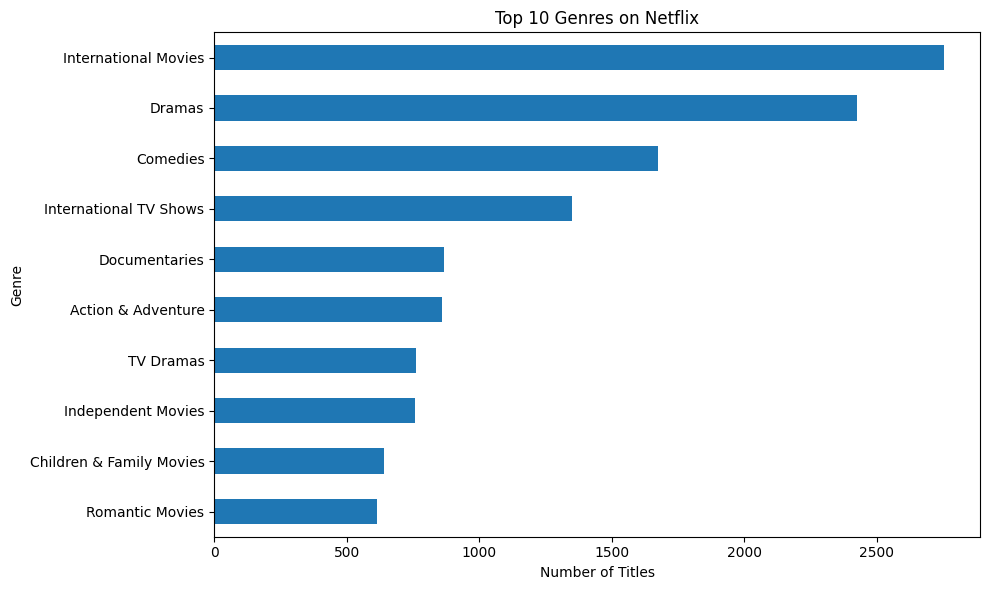

In [17]:
# Split genre lists and count each genre
genre_counts = (
    df_clean["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
    .head(10)
)

print(genre_counts)

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

genre_counts.sort_values().plot(kind="barh")

plt.title("Top 10 Genres on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

Insight 3: Genre Distribution

The genre analysis shows that International Movies is the most frequent category in the top 10, followed by Dramas and Comedies. This indicates that international content and drama-related categories occupy a substantial place in the Netflix catalog. Content strategy teams could examine audience engagement and regional demand for these categories before deciding which genres to prioritize for future acquisitions.



country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


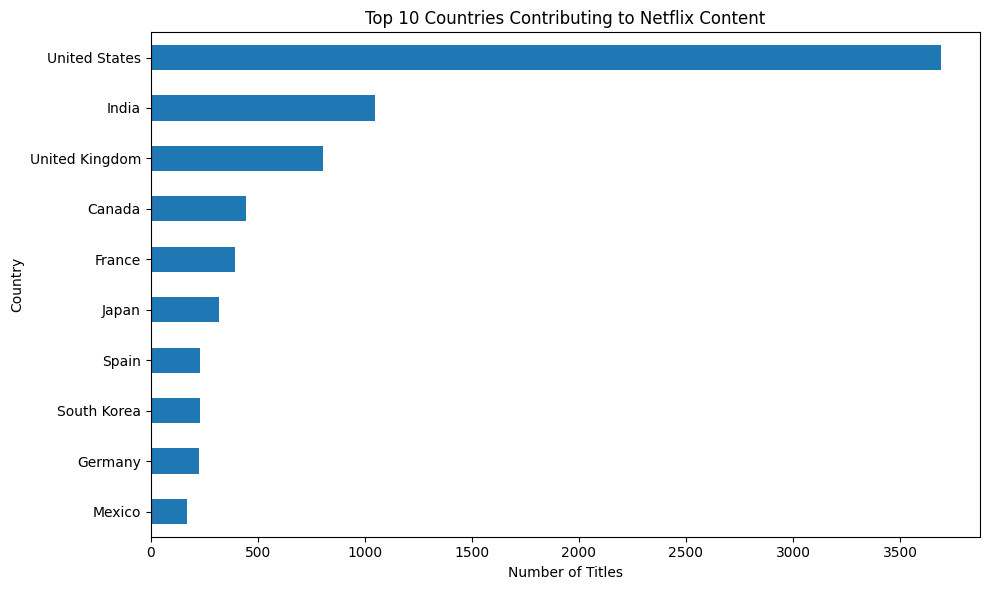

In [18]:
#Top 10 Countries by Number of Titles
country_counts = (
    df_clean.loc[df_clean["country"] != "Unknown", "country"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
    .head(10)
)

print(country_counts)

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

country_counts.sort_values().plot(kind="barh")

plt.title("Top 10 Countries Contributing to Netflix Content")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

Insight 4: Country-wise Content Distribution

The analysis shows that the United States contributes the largest number of titles to Netflix's catalog, with 3,689 country appearances. India ranks second with 1,046, followed by the United Kingdom with 804. This indicates that the catalog has a strong US presence, while India and other countries also contribute substantially. Netflix's content strategy team could investigate regional audience engagement to identify opportunities for further investment in locally relevant content.

rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: count, dtype: int64


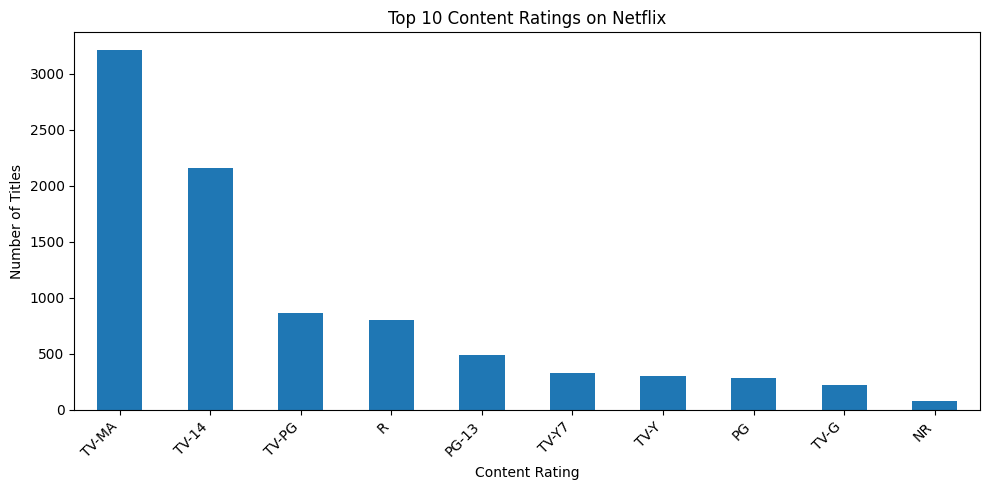

In [19]:
# Distribution of Content Ratings

rating_counts = (
    df_clean["rating"]
    .value_counts()
    .head(10)
)

print(rating_counts)

# Create a bar chart
plt.figure(figsize=(10, 5))

rating_counts.plot(kind="bar")

plt.title("Top 10 Content Ratings on Netflix")
plt.xlabel("Content Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Insight 5: Content Rating Distribution

The analysis shows that TV-MA is the most common content rating, with 3,207 titles, followed by TV-14 with 2,160 titles. Together, these two categories represent approximately 61% of the full Netflix catalog. This indicates a substantial representation of mature and teen-oriented content in the dataset. Content strategy teams could examine audience engagement across age groups to understand whether the current rating mix aligns with their target audiences.

Number of movies analyzed: 6128
Average duration: 99.58 minutes
Median duration: 98.0 minutes


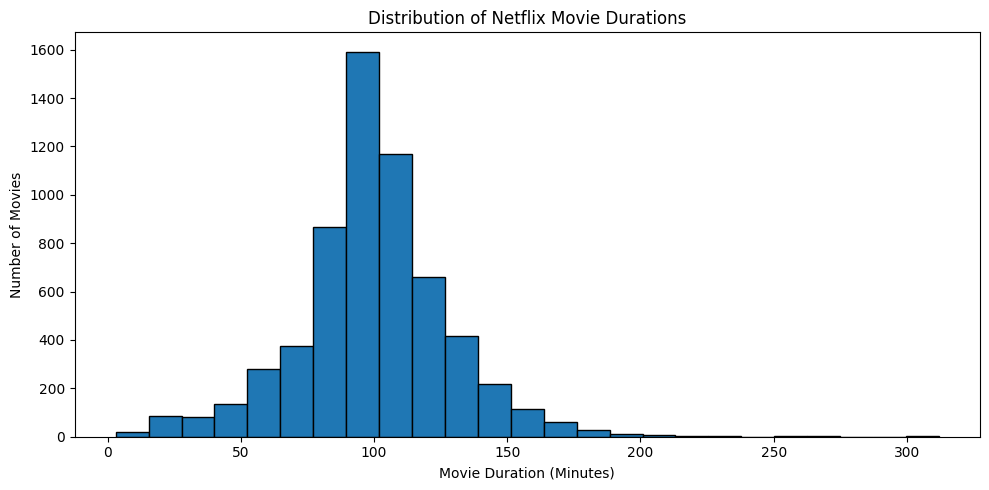

In [20]:
# Distribution of Movie Durations

movies = df_clean[df_clean["type"] == "Movie"].copy()

movies["duration_minutes"] = pd.to_numeric(
    movies["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Remove missing durations
movie_durations = movies["duration_minutes"].dropna()

# Display summary statistics
print("Number of movies analyzed:", len(movie_durations))
print("Average duration:", round(movie_durations.mean(), 2), "minutes")
print("Median duration:", movie_durations.median(), "minutes")

# Create a histogram
plt.figure(figsize=(10, 5))

plt.hist(movie_durations, bins=25, edgecolor="black")

plt.title("Distribution of Netflix Movie Durations")
plt.xlabel("Movie Duration (Minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

Insight 6: Netflix Movie Duration Analysis

The analysis of 6,128 movies shows an average duration of 99.58 minutes and a median duration of 98 minutes. Most movies are concentrated around the 90–110 minute range, indicating that feature-length films of approximately 1.5 to 2 hours are common in the catalog. A smaller number of movies have substantially longer durations. Content strategy teams could use these patterns to understand the existing runtime mix when evaluating future movie acquisitions.

📌 Business Recommendations

1. Evaluate Opportunities to Diversify Content Types
Finding: The dataset contains 6,131 movies and 2,676 TV shows. Movies account for approximately 69.6% of the catalog, while TV shows account for 30.4%.
Recommendation:
- Investigate whether expanding TV show offerings could improve viewer engagement and retention.
- Compare viewing patterns for movies and TV shows before deciding which content type to prioritize.
- Evaluate audience preferences and production costs when planning future content investments.
Expected Business Benefit: This analysis could help Netflix identify opportunities to balance its content library according to audience demand.
2. Explore Regional Content Opportunities
Finding: The United States has the highest country representation in the dataset, with 3,689 titles, followed by India with 1,046 and the United Kingdom with 804.
Recommendation:
- Analyze audience engagement across different countries and regions.
- Investigate opportunities to develop or acquire local-language content in markets with strong audience demand.
- Compare regional genre preferences to identify content opportunities that may appeal to local audiences.
Expected Business Benefit: A region-focused content strategy could help Netflix serve diverse audiences and identify opportunities for international growth.
3. Use Genre and Runtime Trends to Guide Content Planning
Finding: International Movies, Dramas, and Comedies are among the most frequently listed categories. The average movie duration in the dataset is approximately 99.58 minutes.
Recommendation:
- Examine viewer engagement across different genres to identify content that resonates with audiences.
- Evaluate whether movie runtimes vary by genre and audience preference.
- Use viewing data, completion rates, and audience feedback to inform future content acquisition and production decisions.
Expected Business Benefit: Combining catalog trends with audience behavior could help Netflix make more informed decisions about genre selection and content duration.